# AG News Topic Classification
Baseline (TF-IDF + Logistic Regression) vs. fine-tuned DistilBERT.

**Run cells top to bottom, in order.** Each section is self-contained.

If you hit a dependency error, run the install cell below first, then
**restart the kernel** (Kernel > Restart Kernel) before running anything else.

## 0. Install dependencies (run once, then restart kernel)

In [1]:
# Run this cell once. On Mac, torch installs via plain pip (no special index needed).
# After it finishes, restart the kernel (Kernel menu > Restart Kernel), then skip this cell
# and run everything from the next cell down.

%pip install --upgrade pip setuptools wheel
%pip install torch torchvision torchaudio
%pip install datasets transformers scikit-learn matplotlib pandas numpy accelerate

  Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
Using cached setuptools-82.0.1-py3-none-any.whl (1.0 MB)
  Attempting uninstall: wheel
    Found existing installation: wheel 0.45.1
    Uninstalling wheel-0.45.1:
      Successfully uninstalled wheel-0.45.1
  Attempting uninstall: setuptools
    Found existing installation: setuptools 80.9.0
    Uninstalling setuptools-80.9.0:
      Successfully uninstalled setuptools-80.9.0━━━━━━━━━━━━━━━━━━ 1/2 [setuptools]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [setuptools]2 [setuptools]
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 252.0 kB/s  0:00:07 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 92.7 kB/s  0:00:18m0:00:0100:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchaudio]2 [torchaudio]
Note: you may need to restart the kernel to use updated packages.
  Using cached urllib3-2.6.3-py3-none-any.whl.metadata (6.9 kB

## 1. Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from datasets import load_dataset, Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

LABEL_NAMES = ["World", "Sports", "Business", "Sci/Tech"]

## 2. Load the data

This downloads AG News once and caches it locally. **Check the printed sizes** —
they should read `Train size: 120000` and `Test size: 7600`. If you see much
smaller numbers, something truncated the data and the rest of the notebook
will give meaningless results.

In [3]:
dataset = load_dataset("ag_news")

train_texts = dataset["train"]["text"]
train_labels = dataset["train"]["label"]
test_texts = dataset["test"]["text"]
test_labels = dataset["test"]["label"]

print(f"Train size: {len(train_texts)}")
print(f"Test size:  {len(test_texts)}")

print("\nSample:")
print(f"  Label: {LABEL_NAMES[train_labels[0]]}")
print(f"  Text:  {train_texts[0][:150]}...")

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Train size: 120000
Test size:  7600

Sample:
  Label: Business
  Text:  Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....


## 3. Baseline: TF-IDF + Logistic Regression

Trains on the full training set. Should take well under a minute.

In [4]:
vectorizer = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words="english")
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

baseline_clf = LogisticRegression(max_iter=1000, n_jobs=-1)
baseline_clf.fit(X_train, train_labels)

baseline_preds = baseline_clf.predict(X_test)

print("=== Baseline: TF-IDF + Logistic Regression ===")
print(classification_report(test_labels, baseline_preds, target_names=LABEL_NAMES, digits=4))

baseline_acc = accuracy_score(test_labels, baseline_preds)
baseline_f1 = f1_score(test_labels, baseline_preds, average="macro")

=== Baseline: TF-IDF + Logistic Regression ===
              precision    recall  f1-score   support

       World     0.9342    0.9116    0.9227      1900
      Sports     0.9540    0.9816    0.9676      1900
    Business     0.8944    0.8868    0.8906      1900
    Sci/Tech     0.8967    0.9000    0.8983      1900

    accuracy                         0.9200      7600
   macro avg     0.9198    0.9200    0.9198      7600
weighted avg     0.9198    0.9200    0.9198      7600



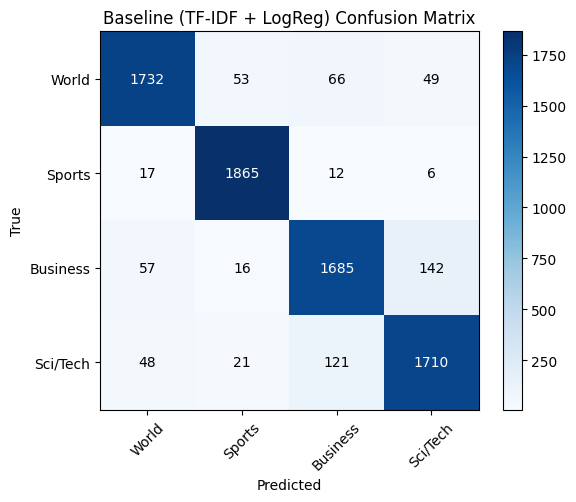

In [5]:
cm = confusion_matrix(test_labels, baseline_preds)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(LABEL_NAMES, rotation=45)
ax.set_yticks(range(4)); ax.set_yticklabels(LABEL_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Baseline (TF-IDF + LogReg) Confusion Matrix")

for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.colorbar(im)
plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png")
plt.show()

## 4. Fine-tune DistilBERT

Uses a subset of the training set (`SUBSET_SIZE`) to keep training time
reasonable on a laptop. Set `SUBSET_SIZE = None` to use the full 120k
training set if you have a GPU — on CPU/MPS this will be much slower.

Automatically uses Apple Silicon's MPS backend if available, otherwise CPU.

In [6]:
SUBSET_SIZE = 8000  # set to None for the full training set
MODEL_NAME = "distilbert-base-uncased"

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

if SUBSET_SIZE is not None:
    hf_train_texts = train_texts[:SUBSET_SIZE]
    hf_train_labels = train_labels[:SUBSET_SIZE]
    print(f"Using a subset of {SUBSET_SIZE} training examples.")
else:
    hf_train_texts = train_texts
    hf_train_labels = train_labels

train_ds = Dataset.from_dict({"text": hf_train_texts, "label": hf_train_labels})
test_ds = Dataset.from_dict({"text": test_texts, "label": test_labels})

Using device: mps
Using a subset of 8000 training examples.


In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)
model.to(device)

def tokenize_fn(examples):
    return tokenizer(examples["text"], truncation=True, padding="max_length", max_length=128)

train_ds = train_ds.map(tokenize_fn, batched=True)
test_ds = test_ds.map(tokenize_fn, batched=True)

train_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
test_ds.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [8]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    report = classification_report(labels, preds, target_names=LABEL_NAMES, output_dict=True)
    return {"accuracy": report["accuracy"], "macro_f1": report["macro avg"]["f1-score"]}

training_args = TrainingArguments(
    output_dir="./distilbert-agnews",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    report_to="none",
    use_mps_device=(device == "mps"),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics,
)

trainer.train()

/Users/hrubaruh/Downloads/dreamer-from-scratch-main/.conda/lib/python3.9/site-packages/transformers/training_args.py:2301: UserWarning: `use_mps_device` is deprecated and will be removed in version 5.0 of 🤗 Transformers. `mps` device will be used by default if available similar to the way `cuda` device is used.Therefore, no action from user is required. 
  warnings.warn(
/Users/hrubaruh/Downloads/dreamer-from-scratch-main/.conda/lib/python3.9/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.303000,0.283354,0.905921,0.905872
2,0.253500,0.340924,0.904474,0.903959
3,0.119100,0.344692,0.911447,0.911562


/Users/hrubaruh/Downloads/dreamer-from-scratch-main/.conda/lib/python3.9/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/Users/hrubaruh/Downloads/dreamer-from-scratch-main/.conda/lib/python3.9/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


TrainOutput(global_step=1500, training_loss=0.22821900590260824, metrics={'train_runtime': 440.8129, 'train_samples_per_second': 54.445, 'train_steps_per_second': 3.403, 'total_flos': 794832740352000.0, 'train_loss': 0.22821900590260824, 'epoch': 3.0})

## 5. Evaluate DistilBERT

In [9]:
predictions = trainer.predict(test_ds)
transformer_preds = np.argmax(predictions.predictions, axis=-1)
transformer_labels = predictions.label_ids

print("=== DistilBERT (fine-tuned) ===")
print(classification_report(transformer_labels, transformer_preds, target_names=LABEL_NAMES, digits=4))

transformer_acc = accuracy_score(transformer_labels, transformer_preds)
transformer_f1 = f1_score(transformer_labels, transformer_preds, average="macro")

/Users/hrubaruh/Downloads/dreamer-from-scratch-main/.conda/lib/python3.9/site-packages/torch/utils/data/dataloader.py:684: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, then device pinned memory won't be used.
  warnings.warn(warn_msg)


=== DistilBERT (fine-tuned) ===
              precision    recall  f1-score   support

       World     0.9264    0.9211    0.9237      1900
      Sports     0.9792    0.9668    0.9730      1900
    Business     0.8765    0.8553    0.8657      1900
    Sci/Tech     0.8657    0.9026    0.8838      1900

    accuracy                         0.9114      7600
   macro avg     0.9120    0.9114    0.9116      7600
weighted avg     0.9120    0.9114    0.9116      7600



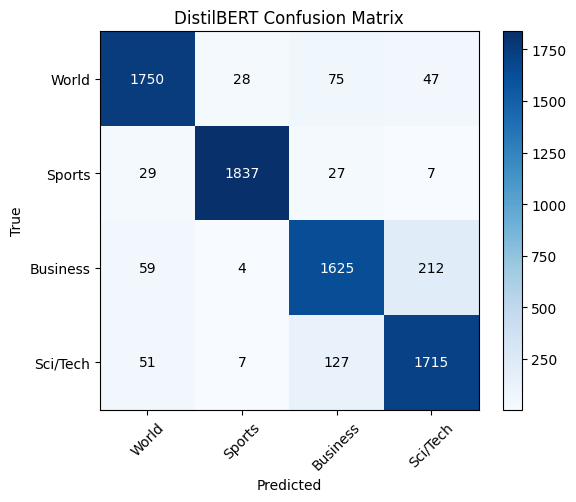

In [10]:
cm2 = confusion_matrix(transformer_labels, transformer_preds)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm2, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(LABEL_NAMES, rotation=45)
ax.set_yticks(range(4)); ax.set_yticklabels(LABEL_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("DistilBERT Confusion Matrix")

for i in range(4):
    for j in range(4):
        ax.text(j, i, cm2[i, j], ha="center", va="center",
                color="white" if cm2[i, j] > cm2.max() / 2 else "black")

plt.colorbar(im)
plt.tight_layout()
plt.savefig("distilbert_confusion_matrix.png")
plt.show()

## 6. Compare baseline vs. DistilBERT

In [11]:
print("=== Summary ===")
print(f"Baseline (TF-IDF + LogReg): accuracy={baseline_acc:.4f}, macro-F1={baseline_f1:.4f}")
print(f"DistilBERT (fine-tuned):    accuracy={transformer_acc:.4f}, macro-F1={transformer_f1:.4f}")

=== Summary ===
Baseline (TF-IDF + LogReg): accuracy=0.9200, macro-F1=0.9198
DistilBERT (fine-tuned):    accuracy=0.9114, macro-F1=0.9116


## 7. Qualitative error analysis

Pulls a few test examples where the baseline was wrong but DistilBERT was
right, and vice versa — useful for the report's error-analysis section.

In [12]:
baseline_wrong_transformer_right = []
transformer_wrong_baseline_right = []

for i in range(len(test_labels)):
    true = test_labels[i]
    b_pred = baseline_preds[i]
    t_pred = transformer_preds[i]

    if b_pred != true and t_pred == true and len(baseline_wrong_transformer_right) < 5:
        baseline_wrong_transformer_right.append((test_texts[i], true, b_pred, t_pred))

    if t_pred != true and b_pred == true and len(transformer_wrong_baseline_right) < 5:
        transformer_wrong_baseline_right.append((test_texts[i], true, b_pred, t_pred))

print("--- Baseline wrong, DistilBERT right ---")
for text, true, b_pred, t_pred in baseline_wrong_transformer_right:
    print(f"True: {LABEL_NAMES[true]} | Baseline said: {LABEL_NAMES[b_pred]} | DistilBERT said: {LABEL_NAMES[t_pred]}")
    print(f"Text: {text[:200]}")
    print()

print("--- DistilBERT wrong, Baseline right ---")
for text, true, b_pred, t_pred in transformer_wrong_baseline_right:
    print(f"True: {LABEL_NAMES[true]} | Baseline said: {LABEL_NAMES[b_pred]} | DistilBERT said: {LABEL_NAMES[t_pred]}")
    print(f"Text: {text[:200]}")
    print()

--- Baseline wrong, DistilBERT right ---
True: Sci/Tech | Baseline said: Business | DistilBERT said: Sci/Tech
Text: IBM to hire even more new workers By the end of the year, the computing giant plans to have its biggest headcount since 1991.

True: Sci/Tech | Baseline said: Business | DistilBERT said: Sci/Tech
Text: Rivals Try to Turn Tables on Charles Schwab By MICHAEL LIEDTKE     SAN FRANCISCO (AP) -- With its low prices and iconoclastic attitude, discount stock broker Charles Schwab Corp. (SCH) represented an 

True: World | Baseline said: Business | DistilBERT said: World
Text: India's Tata expands regional footprint via NatSteel buyout (AFP) AFP - India's Tata Iron and Steel Company Ltd. took a strategic step to expand its Asian footprint with the announcement it will buy t

True: World | Baseline said: Business | DistilBERT said: World
Text: Stocks Climb on Drop in Consumer Prices NEW YORK - Stocks rose for a second straight session Tuesday as a drop in consumer prices allowed in